# `greggjuri/golf-swing-analyzer`: component benchmark

**Classification: Level B — meaningful components executed, not an end-to-end application run.** Reviewed at commit `13669643f8ed8865df74f2fe1239b126f067120c` (2025-12-07). The exact video loader, whole-frame motion event detector, Canny/Hough club detector, and tracker ran on the shared `00001.mov`. The GUI cannot complete analysis against the checked-out APIs, and the pose class intentionally raises `NotImplementedError` when MediaPipe is installed.

This notebook reads evidence generated by `scripts/benchmark_repository_components.py`; it does not copy or repair upstream algorithms.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
pd.set_option("display.max_colwidth", 100)

out = ROOT / "outputs/greggjuri"
summary = json.loads((out / "00001_summary.json").read_text())
tests = json.loads((out / "test_summary.json").read_text())
motion = pd.read_csv(out / "00001_motion.csv")
club = pd.read_csv(out / "00001_club_tracking.csv")
manual = pd.read_csv(out / "00001_manual_label_comparison.csv")
display(pd.Series(summary, name="observed result").to_frame())
display(pd.Series(tests, name="test evidence").to_frame())

,observed result
python,3.9.25
opencv,4.11.0
numpy,1.26.4
scipy,1.13.1
sample,data/raw/golftracker_samples/00001.mov
frames,136
fps,30.0
event_positions,"{'P1': 20, 'P4': 40, 'P7': 88}"
event_runtime_seconds,0.184886
club_runtime_seconds,0.984641


,test evidence
environment,envs/swing-analyzer
python,3.11
opencv,5.0.0
result,"325 passed, 21 failed"
passed,325
failed,21
failure_groups,"{'club_detector_opencv_5_hough_shape': 7, 'pose_and_integration_mediapipe_placeholder': 14}"
interpretation,"The suite is substantial, but the checked-out implementation neither completes MediaPipe integra..."


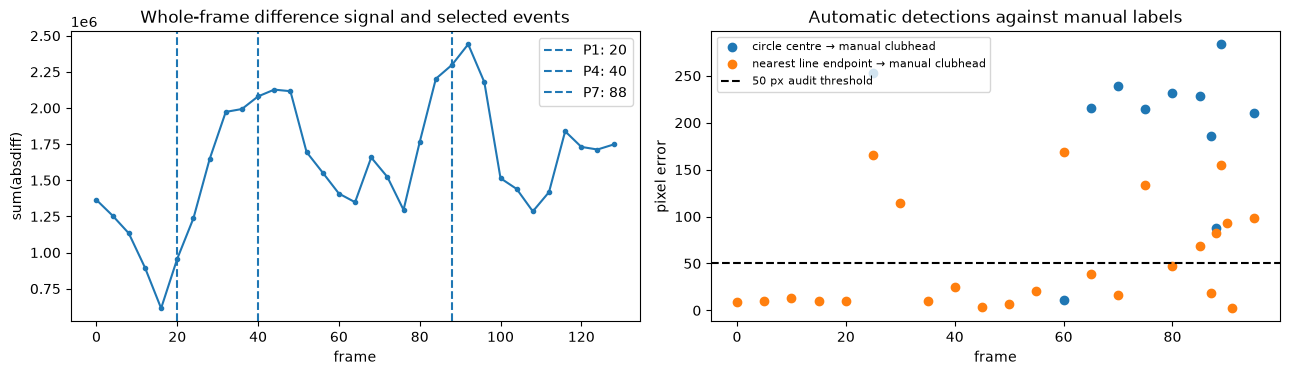

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(motion.transition_from_frame, motion.motion_sum, marker="o", ms=3)
for label, frame in summary["event_positions"].items():
    axes[0].axvline(frame, ls="--", label=f"{label}: {frame}")
axes[0].set(title="Whole-frame difference signal and selected events", xlabel="frame", ylabel="sum(absdiff)")
axes[0].legend()

available = manual.dropna(subset=["club_head_error_px"])
axes[1].scatter(available.frame, available.club_head_error_px, label="circle centre → manual clubhead")
axes[1].scatter(manual.frame, manual.nearest_shaft_endpoint_error_px, label="nearest line endpoint → manual clubhead")
axes[1].axhline(50, color="black", ls="--", label="50 px audit threshold")
axes[1].set(title="Automatic detections against manual labels", xlabel="frame", ylabel="pixel error")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## Source and run audit

- `ClubDetector` applies grayscale/blur/Canny, `HoughLinesP`, and `HoughCircles`. It chooses the longest line and assigns every detected circle confidence 0.7. It does not identify which pixels belong to the club.
- `ClubTracker` is a causal moving average plus last-value gap hold. Contrary to README wording, there is no Kalman filter in the tracker.
- `KeyPositionDetector` uses full-frame absolute differences—not optical flow. After Gaussian smoothing it picks P1 from a low-motion window, P4 from the first local peak (or global fallback), and P7 from the largest post-P4 whole-frame motion.
- On OpenCV 4.11, a shaft was returned on 136/136 frames and a clubhead circle on 90/136. Against 24 existing manual labels, clubhead availability was 11 and only 1/24 labels was within 50 px. This is evidence of false-positive-prone detection, not successful club tracking.
- The test suite produced 325 passes and 21 failures in the isolated OpenCV 5 environment. Seven club failures result from an unhandled Hough output-shape change; fourteen pose/integration failures reach the deliberate MediaPipe placeholder.
- The GUI calls constructors/methods with incompatible signatures (`KeyPositionDetector`, nonexistent `track_sequence` methods), treats dataclasses as dictionaries, and sends tuple geometry to an API expecting `ShaftPosition`. Export/navigation widgets exist, but the integrated analysis path is not operational at this commit.
- Swing-plane code operates on supplied/projected shaft positions; the checked-out GUI does not create a calibrated 3-D shaft trajectory from detector output. Synchronization is a manual fixed frame offset. Difference overlays are frame blends, not biomechanical alignment.

In [3]:
audit = pd.DataFrame([
    ("video decode", "observed", "Exact VideoLoader on 136-frame shared clip"),
    ("body pose", "not implemented", "PoseDetector raises: MediaPipe integration pending"),
    ("club/shaft", "observed but unreliable", "Hough outputs compared with manual labels"),
    ("events", "observed heuristic", "P1/P4/P7 from whole-frame absdiff"),
    ("continuous export", "partial", "Derived club CSV; no body trajectory"),
    ("end-to-end GUI", "broken", "API mismatches in checked-out source"),
], columns=["capability", "status", "evidence"])
display(audit)
print("EXECUTED_OK: greggjuri component notebook")

,capability,status,evidence
0,video decode,observed,Exact VideoLoader on 136-frame shared clip
1,body pose,not implemented,PoseDetector raises: MediaPipe integration pending
2,club/shaft,observed but unreliable,Hough outputs compared with manual labels
3,events,observed heuristic,P1/P4/P7 from whole-frame absdiff
4,continuous export,partial,Derived club CSV; no body trajectory
5,end-to-end GUI,broken,API mismatches in checked-out source


EXECUTED_OK: greggjuri component notebook


## Reuse decision

Use the detector only as a negative/control baseline for labelled club-point evaluation. The clean dataclass boundaries and video seeking utilities are adaptable. Do not reuse the event labels as ground truth, the club detections as measurements, or any swing-plane result until calibration and coordinate flow are made explicit. There is no licence file in the clone, so README/badge statements are insufficient reuse permission.